In [2]:
import geopandas as gpd
import pandas as pd

1. Dla warstwy z rzekami policz ile jest obiektów których MultiLineString zawiera dokładnie między 2 a 10 części składowych geometrii

In [3]:
path_to_files = "../dane/"
rivers = gpd.read_file(path_to_files+"hr1.geojson")

rivers["liczba_poligonow"] = rivers.geometry.apply(lambda geom: len(geom.geoms))

wynik = (
    rivers.loc[rivers["liczba_poligonow"].between(2, 10), ["nazwa", "liczba_poligonow"]]
)
wynik

,nazwa,liczba_poligonow
3,Missisipi,10
5,Wołga,8
6,Jangcy,5
11,Fuerte,2
12,Machado,2
...,...,...
729,Kaweri,4
730,Kuanza,2
732,Mekong,7
733,Nil Błękitny,3


2. Dla warstwy demograficznej wyświetl na mapie kraje, w których odsetek osób w wieku 65+ wynosi ponad 18%

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

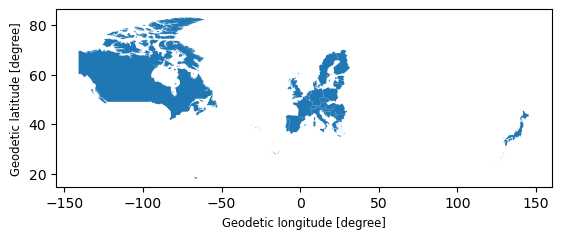

In [4]:
demography = gpd.read_file(path_to_files+"lsp1.geojson")

col = "ludność_w_wieku_65_lat_i_więcej"

demography[col] = pd.to_numeric(
    demography[col]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
    .replace("brak danych", pd.NA),
    errors="coerce",
)

wynik = demography[demography["ludność_w_wieku_65_lat_i_więcej"] > 18]
wynik.plot()

3. Dla warstwy z wulkanami stwórz podzbiór wulkanów znajdujących się w Stanach Zjednoczonych. Następnie wypisz wszystkie typy wulkanów występujące w tym podzbiorze oraz oblicz, jaki procent wszystkich wulkanów w USA stanowi każdy z typów

In [8]:
path_to_files = "../dane/wulkany/"
geojson_v = gpd.read_file(path_to_files+"lw1.geojson")
vulcans = geojson_v

vulcans_usa = vulcans[vulcans["kraj"].str.contains("Stany Zjednoczone", case=True, na=False)]

print((vulcans_usa["typ"].value_counts(dropna=False, normalize=True) * 100).round(2))

typ
stratowulkan         51.19
tarczowy             11.90
podwodny             10.71
pole wulkaniczne      8.93
stożkowy              7.14
kopuła lawowa         3.57
maar                  2.98
kaldera               2.98
mieszane, złożone     0.60
Name: proportion, dtype: float64
